## Load Model

In [1]:
import numpy as np
import torch
import os

from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

%load_ext autoreload
%autoreload 2

from utils import generate_run_ID
from place_cells import PlaceCells
from direction_cells import DirectionCells
from trajectory_generator import TrajectoryGenerator
from models import LMN_PaS_Conj_mEC
from trainer import Trainer

In [2]:
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer/' 
options.n_steps = 1000    # number of training steps
options.epochs = 201       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-8 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512           # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.use_pas_layernorm = False  # apply LayerNorm to PaS before feeding Conj
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)



Restored trained model from ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth


In [3]:
#Run Model Simulation
from visualize import compute_ratemaps_dc_lmn_pas, compute_lmn_ratemaps_by_rotation_trueangle
from trajectory_generator_seed import TrajectoryGenerator

options.sequence_length = 100
options.batch_size = 20
model.eval()

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=None)

results = compute_ratemaps_dc_lmn_pas(
    model, trajectory_generator, options,
    res=60, n_avg=100,
    N_lmn=options.Nlmn, N_pas=options.Npas,
)
activations_lmn, rate_map_lmn, activations_pas, rate_map_pas, lmn, pas, ang = results

results_rot = compute_lmn_ratemaps_by_rotation_trueangle(
    model=model,
    trajectory_generator=trajectory_generator,
    options=options,
    res=60,
    n_avg=100,
    N_lmn=options.Nlmn,
    idxs_lmn=None,
    zero_tol=1e-8,
    target_alignment="post_update",   # change to "pre_update" if needed
)


activations_lmn_ccw = results_rot["ccw"]["activations_lmn"]
activations_lmn_cw  = results_rot["cw"]["activations_lmn"]

### 1 Flux Analysis of LMN Ring Attractor

flip_sign = 1.0
theta_offset = 0.15607314


/tmp/ipykernel_515487/1344301421.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


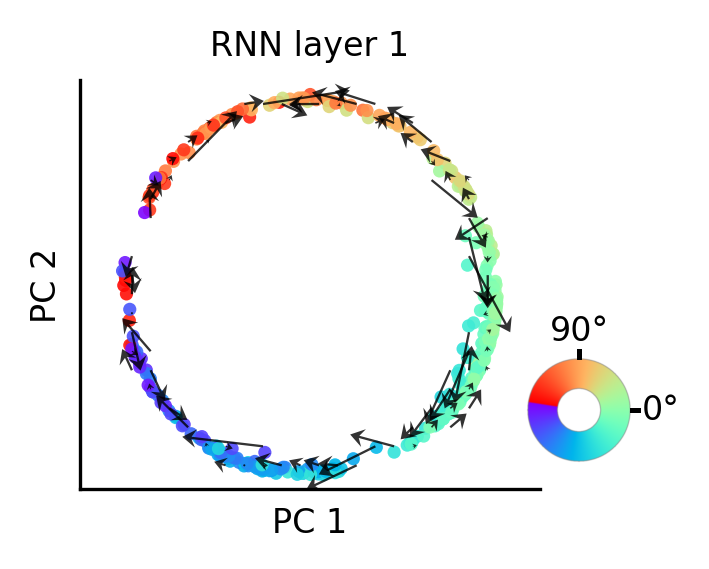

In [4]:
#Flux

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.colors import Normalize


trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=None)
options.sequence_length = 20
inputs, dc_outputs, mdir = trajectory_generator.get_test_batch()

with torch.no_grad():
    lmn = model.Lmn(inputs)  # lmn: [T,B,N]

T, B, N = lmn.shape
lmn = lmn.cpu().numpy()
lmn = lmn.transpose(1, 0, 2).reshape(-1, N)  # (B*T, N)

lmn_z = StandardScaler().fit_transform(lmn)

# PCA
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(lmn_z)

# 颜色
colors = mdir.detach().cpu().numpy().transpose(1, 0).reshape(-1)

# --------------------------------------------------
# flux in 2D PCA subspace using 10x10 spatial bins
# --------------------------------------------------
n_bins = 20

# reshape back to trial x time x 2 so we only use within-trial transitions
X_pca_trials = X_pca.reshape(B, T, 2)

# position at time t and displacement to t+1
X_pca_pos = X_pca_trials[:, :-1, :].reshape(-1, 2)              # [(B*(T-1)), 2]
X_pca_vel = (X_pca_trials[:, 1:, :] - X_pca_trials[:, :-1, :]).reshape(-1, 2)

x = X_pca_pos[:, 0]
y = X_pca_pos[:, 1]
u = X_pca_vel[:, 0]
v = X_pca_vel[:, 1]

x_edges = np.linspace(x.min(), x.max(), n_bins + 1)
y_edges = np.linspace(y.min(), y.max(), n_bins + 1)

x_bin = np.digitize(x, x_edges) - 1
y_bin = np.digitize(y, y_edges) - 1

x_bin = np.clip(x_bin, 0, n_bins - 1)
y_bin = np.clip(y_bin, 0, n_bins - 1)

flux_u = np.full((n_bins, n_bins), np.nan)
flux_v = np.full((n_bins, n_bins), np.nan)
counts = np.zeros((n_bins, n_bins), dtype=int)

sum_u = np.zeros((n_bins, n_bins), dtype=float)
sum_v = np.zeros((n_bins, n_bins), dtype=float)

for i in range(len(x)):
    sum_u[y_bin[i], x_bin[i]] += u[i]
    sum_v[y_bin[i], x_bin[i]] += v[i]
    counts[y_bin[i], x_bin[i]] += 1

valid = counts > 0
flux_u[valid] = sum_u[valid] / counts[valid]
flux_v[valid] = sum_v[valid] / counts[valid]

x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
Xc, Yc = np.meshgrid(x_centers, y_centers)

fig, ax = plt.subplots(1, 1, figsize=(2, 2), dpi=300)

# flux vectors
mask = np.isfinite(flux_u) & np.isfinite(flux_v)
ax.quiver(
    Xc[mask],
    Yc[mask],
    flux_u[mask],
    flux_v[mask],
    angles='xy',
    scale_units='xy',
    scale=None,
    color='black',
    width=0.005,
    headwidth=8,
    headlength=6,
    headaxislength=4.0,
    alpha=0.8,
    zorder=3,
)


for trial_idx in range(50):
    start = trial_idx * T
    chunk = X_pca[start:start + T]
    colors_trial = colors[start:start + T]
    ax.scatter(
        chunk[:, 0],
        chunk[:, 1],
        c=colors_trial,
        cmap="rainbow",
        s=10,
        edgecolor='none',
        vmin=-np.pi,
        vmax=np.pi,
        alpha=0.9,
    )

# nbin x nbin spatial bin grid
#for xe in x_edges:
#    ax.plot([xe, xe], [y_edges[0], y_edges[-1]], color='lightgray', lw=0.4, alpha=0.6, zorder=0)
#for ye in y_edges:
#    ax.plot([x_edges[0], x_edges[-1]], [ye, ye], color='lightgray', lw=0.4, alpha=0.6, zorder=0)


# ax.set_title("PCA")
ax.set_xlabel("PC 1", fontsize=8)
ax.set_ylabel("PC 2", fontsize=8)
ax.axis('equal')
#tick off
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("RNN layer 1", fontsize=8)

sns.despine()

# 在主图里嵌一个 ring legend
# --------------------------------------------------
# make ring legend visually align with the PCA ring
# --------------------------------------------------

# estimate center of the PCA ring from the plotted points
cx = np.mean(X_pca[:, 0])
cy = np.mean(X_pca[:, 1])

# geometric angle of each PCA point around the ring center
theta_pca = np.arctan2(X_pca[:, 1] - cy, X_pca[:, 0] - cx)

# color angle
theta_col = colors.copy()

def circdiff(a, b):
    return np.angle(np.exp(1j * (a - b)))

# case 1: no flip
offset1 = np.angle(np.mean(np.exp(1j * (theta_col - theta_pca))))
err1 = np.mean(np.abs(circdiff(theta_col, theta_pca + offset1)))

# case 2: flipped direction
offset2 = np.angle(np.mean(np.exp(1j * (theta_col + theta_pca))))
err2 = np.mean(np.abs(circdiff(theta_col, -theta_pca + offset2)))

if err1 <= err2:
    flip_sign = 1.0
    theta_offset = offset1
else:
    flip_sign = -1.0
    theta_offset = offset2

print("flip_sign =", flip_sign)
print("theta_offset =", theta_offset)

# --------------------------------------------------
# ring legend
# --------------------------------------------------
ring_ax = fig.add_axes([0.9, 0.2, 0.18, 0.18])
ring_ax.set_xlim(-1, 1)
ring_ax.set_ylim(-1, 1)
ring_ax.axis("off")

grid = 400
xs = np.linspace(-1, 1, grid)
ys = np.linspace(-1, 1, grid)
XX, YY = np.meshgrid(xs, ys)
RR = np.sqrt(XX**2 + YY**2)

TH = np.arctan2(YY, XX)
TH = flip_sign * TH + theta_offset
TH = (TH + np.pi) % (2*np.pi) - np.pi

mask = (RR < 0.4) | (RR > 0.95)
Z = TH.copy()
Z[mask] = np.nan

ring_ax.imshow(
    Z,
    cmap="rainbow",
    extent=(-1, 1, -1, 1),
    origin="lower",
    norm=Normalize(vmin=-np.pi, vmax=np.pi),
    interpolation="bicubic",
)

# ticks stay at geometric right/top
ring_ax.plot([0.98, 1.10], [0.0, 0.0], color="black", lw=1.2, clip_on=False)
ring_ax.text(1.16, 0.0, "0°", va="center", ha="left", fontsize=8, clip_on=False)

ring_ax.plot([0.0, 0.0], [0.98, 1.10], color="black", lw=1.2, clip_on=False)
ring_ax.text(0.0, 1.16, "90°", va="bottom", ha="center", fontsize=8, clip_on=False)


# ring_ax.set_title("Movement\ndirection", fontsize=10)

plt.tight_layout()

plt.savefig(
    "./docs/lmn_ringattractor_flux.pdf",
    bbox_inches="tight",
    pad_inches=0.05,
)


### 2 Flux Analysis of PaS Ring Attractor

flip_sign = 1.0
theta_offset = 0.7370023


/tmp/ipykernel_515487/3505605807.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


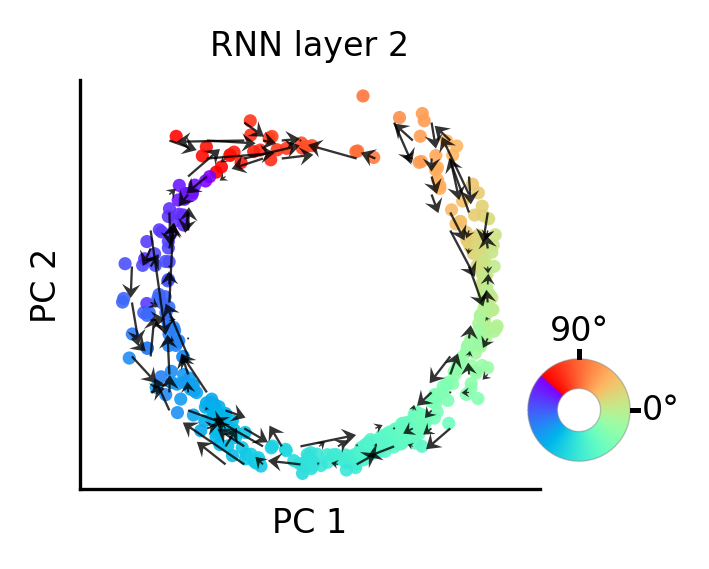

In [5]:
# Flux on PaS manifold
# PaS Attractor

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=None)
options.sequence_length = 20
inputs, dc_outputs, mdir = trajectory_generator.get_test_batch()


with torch.no_grad():
    lmn = model.Lmn(inputs)                  # [T, B, Nlmn]
    pas = model.PaS(lmn, inputs[1])         # [T, B, Npas]

T, B, N = pas.shape
pas = pas.cpu().numpy()
pas = pas.transpose(1, 0, 2).reshape(-1, N)   # (B*T, N)

pas_z = StandardScaler().fit_transform(pas)

# PCA
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(pas_z)

# colors from true movement direction
colors = mdir.detach().cpu().numpy().transpose(1, 0).reshape(-1)

# --------------------------------------------------
# flux in 2D PCA subspace using spatial bins
# --------------------------------------------------
n_bins = 20

# reshape back to trial x time x 2 so we only use within-trial transitions
X_pca_trials = X_pca.reshape(B, T, 2)

# position at time t and displacement to t+1
X_pca_pos = X_pca_trials[:, :-1, :].reshape(-1, 2)              # [(B*(T-1)), 2]
X_pca_vel = (X_pca_trials[:, 1:, :] - X_pca_trials[:, :-1, :]).reshape(-1, 2)

x = X_pca_pos[:, 0]
y = X_pca_pos[:, 1]
u = X_pca_vel[:, 0]
v = X_pca_vel[:, 1]

x_edges = np.linspace(x.min(), x.max(), n_bins + 1)
y_edges = np.linspace(y.min(), y.max(), n_bins + 1)

x_bin = np.digitize(x, x_edges) - 1
y_bin = np.digitize(y, y_edges) - 1

x_bin = np.clip(x_bin, 0, n_bins - 1)
y_bin = np.clip(y_bin, 0, n_bins - 1)

flux_u = np.full((n_bins, n_bins), np.nan)
flux_v = np.full((n_bins, n_bins), np.nan)
counts = np.zeros((n_bins, n_bins), dtype=int)

sum_u = np.zeros((n_bins, n_bins), dtype=float)
sum_v = np.zeros((n_bins, n_bins), dtype=float)

for i in range(len(x)):
    sum_u[y_bin[i], x_bin[i]] += u[i]
    sum_v[y_bin[i], x_bin[i]] += v[i]
    counts[y_bin[i], x_bin[i]] += 1

valid = counts > 0
flux_u[valid] = sum_u[valid] / counts[valid]
flux_v[valid] = sum_v[valid] / counts[valid]

x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
Xc, Yc = np.meshgrid(x_centers, y_centers)

fig, ax = plt.subplots(1, 1, figsize=(2, 2), dpi=300)

# flux vectors
mask_flux = np.isfinite(flux_u) & np.isfinite(flux_v)
ax.quiver(
    Xc[mask_flux],
    Yc[mask_flux],
    flux_u[mask_flux],
    flux_v[mask_flux],
    angles='xy',
    scale_units='xy',
    scale=None,
    color='black',
    width=0.005,
    headwidth=8,
    headlength=6,
    headaxislength=4.0,
    alpha=0.8,
    zorder=3,
)

# PaS trajectory points
n_plot_trials = min(50, B)
for trial_idx in range(n_plot_trials):
    start = trial_idx * T
    chunk = X_pca[start:start + T]
    colors_trial = colors[start:start + T]
    ax.scatter(
        chunk[:, 0],
        chunk[:, 1],
        c=colors_trial,
        cmap="rainbow",
        s=10,
        edgecolor='none',
        vmin=-np.pi,
        vmax=np.pi,
        alpha=0.9,
    )

ax.set_xlabel("PC 1", fontsize=8)
ax.set_ylabel("PC 2", fontsize=8)
ax.axis('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("RNN layer 2", fontsize=8)

sns.despine()

# --------------------------------------------------
# make ring legend visually align with the PaS PCA ring
# --------------------------------------------------

# estimate center of the PCA ring from the plotted points
cx = np.mean(X_pca[:, 0])
cy = np.mean(X_pca[:, 1])

# geometric angle of each PCA point around the ring center
theta_pca = np.arctan2(X_pca[:, 1] - cy, X_pca[:, 0] - cx)

# color angle
theta_col = colors.copy()

def circdiff(a, b):
    return np.angle(np.exp(1j * (a - b)))

# case 1: no flip
offset1 = np.angle(np.mean(np.exp(1j * (theta_col - theta_pca))))
err1 = np.mean(np.abs(circdiff(theta_col, theta_pca + offset1)))

# case 2: flipped direction
offset2 = np.angle(np.mean(np.exp(1j * (theta_col + theta_pca))))
err2 = np.mean(np.abs(circdiff(theta_col, -theta_pca + offset2)))

if err1 <= err2:
    flip_sign = 1.0
    theta_offset = offset1
else:
    flip_sign = -1.0
    theta_offset = offset2

print("flip_sign =", flip_sign)
print("theta_offset =", theta_offset)

# --------------------------------------------------
# ring legend
# --------------------------------------------------
ring_ax = fig.add_axes([0.9, 0.2, 0.18, 0.18])
ring_ax.set_xlim(-1, 1)
ring_ax.set_ylim(-1, 1)
ring_ax.axis("off")

grid = 400
xs = np.linspace(-1, 1, grid)
ys = np.linspace(-1, 1, grid)
XX, YY = np.meshgrid(xs, ys)
RR = np.sqrt(XX**2 + YY**2)

TH = np.arctan2(YY, XX)
TH = flip_sign * TH + theta_offset
TH = (TH + np.pi) % (2*np.pi) - np.pi

mask_ring = (RR < 0.4) | (RR > 0.95)
Z = TH.copy()
Z[mask_ring] = np.nan

ring_ax.imshow(
    Z,
    cmap="rainbow",
    extent=(-1, 1, -1, 1),
    origin="lower",
    norm=Normalize(vmin=-np.pi, vmax=np.pi),
    interpolation="bicubic",
)

# ticks stay at geometric right/top
ring_ax.plot([0.98, 1.10], [0.0, 0.0], color="black", lw=1.2, clip_on=False)
ring_ax.text(1.16, 0.0, "0°", va="center", ha="left", fontsize=8, clip_on=False)

ring_ax.plot([0.0, 0.0], [0.98, 1.10], color="black", lw=1.2, clip_on=False)
ring_ax.text(0.0, 1.16, "90°", va="bottom", ha="center", fontsize=8, clip_on=False)

#title


plt.tight_layout()


plt.savefig(
    "./docs/pas_ringattractor_flux.pdf",
    bbox_inches="tight",
    pad_inches=0.05,
)


### 3, Histogram of Lmn input weights by CCW/CW peak firing rate ratio

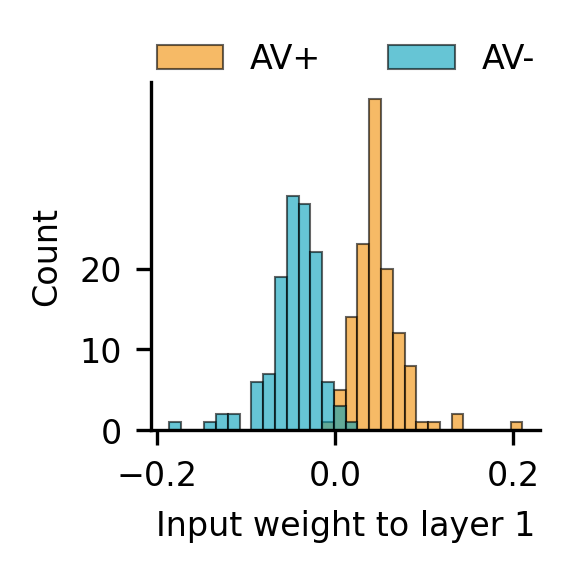

In [6]:
import seaborn as sns
from trajectory_generator_seed import TrajectoryGenerator

# LMN input weights
model.eval()
W_in = model.LmnRNN.weight_ih_l0.detach().cpu().numpy()   # shape usually [Nlmn, input_dim]

# --------------------------------------------------
# CCW / CW ratemaps
# --------------------------------------------------
# preferred direction order from all-condition ratemap
pref_bin = np.argmax(activations_lmn, axis=1)

# peak firing rate ratio
peak_ccw = np.max(activations_lmn_ccw, axis=1)
peak_cw  = np.max(activations_lmn_cw, axis=1)

eps = 1e-12
ratio = peak_ccw / (peak_cw + eps)

# groups
idx_gt1 = np.where(ratio > 1)[0]   # CCW/CW > 1
idx_lt1 = np.where(ratio < 1)[0]   # CCW/CW < 1

# sort each group by preferred direction
idx_gt1 = idx_gt1[np.argsort(pref_bin[idx_gt1])]
idx_lt1 = idx_lt1[np.argsort(pref_bin[idx_lt1])]


# pool all raw signed input weights in each group
w_gt1 = W_in[idx_gt1].ravel()
w_lt1 = W_in[idx_lt1].ravel()

all_w = np.concatenate([w_gt1, w_lt1])
bins = np.linspace(all_w.min(), all_w.max(), 31)

plt.figure(figsize=(2.0,2.1), dpi=300)

plt.hist(
    w_gt1,
    bins=bins,
    alpha=0.6,
    color='#F18D00',
    label=f'AV+',
    edgecolor="black",
    linewidth=0.5,
)

plt.hist(
    w_lt1,
    bins=bins,
    alpha=0.6,
    color='#009FB9',
    label=f'AV-',
    edgecolor="black",
    linewidth=0.5,
)

plt.xlabel("Input weight to layer 1", fontsize=8)
plt.ylabel("Count", fontsize=8)
#tick size as 8
plt.xticks(fontsize=8)
plt.yticks([0,10,20], fontsize=8)


plt.legend(
    fontsize=8,
    loc = 'upper center',
    bbox_to_anchor=(0.5, 1.2),
    ncol=2, 
    frameon=False
)

sns.despine()

plt.tight_layout()

plt.savefig("./docs/layer1_input_weight_histogram.pdf")

#### 4 LMN Recurrent Weight Matrices

Number of LMN cells with input weight > 0: 130
Number of LMN cells with input weight < 0: 126
Number of LMN cells with input weight ≈ 0: 0


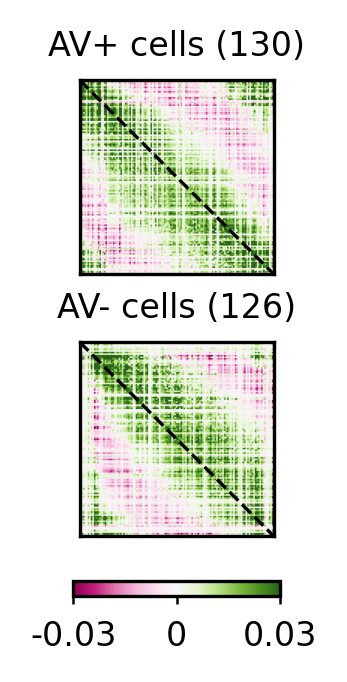

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# LMN recurrent matrix
# --------------------------------------------------
W_lmn = model.LmnRNN.weight_hh_l0.detach().cpu().numpy()

# --------------------------------------------------
# LMN input weights
# --------------------------------------------------
W_input = model.LmnRNN.weight_ih_l0.detach().cpu().numpy()   # [N_lmn, input_dim]

# preferred direction order from all-condition ratemap
pref_bin = np.argmax(activations_lmn, axis=1)

# --------------------------------------------------
# group cells by input-weight sign
# --------------------------------------------------
if W_input.ndim == 2 and W_input.shape[1] == 1:
    input_val = W_input[:, 0]
else:
    input_val = W_input.mean(axis=1)

idx_pos = np.where(input_val > 0)[0]
idx_neg = np.where(input_val < 0)[0]
idx_zero = np.where(np.isclose(input_val, 0.0))[0]

# sort each group by preferred direction
idx_pos = idx_pos[np.argsort(pref_bin[idx_pos])]
idx_neg = idx_neg[np.argsort(pref_bin[idx_neg])]

# --------------------------------------------------
# within-group recurrent submatrices
# --------------------------------------------------
W_pos_to_pos = W_lmn[np.ix_(idx_pos, idx_pos)]
W_neg_to_neg = W_lmn[np.ix_(idx_neg, idx_neg)]

print(f"Number of LMN cells with input weight > 0: {len(idx_pos)}")
print(f"Number of LMN cells with input weight < 0: {len(idx_neg)}")
print(f"Number of LMN cells with input weight ≈ 0: {len(idx_zero)}")

# --------------------------------------------------
# common color scale
# --------------------------------------------------
if (W_pos_to_pos.size + W_neg_to_neg.size) > 0:
    all_vals_W = np.concatenate([W_pos_to_pos.ravel(), W_neg_to_neg.ravel()])
    vW = np.percentile(np.abs(all_vals_W), 95)
else:
    vW = 1.0

if vW == 0:
    vW = 1.0

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
})

# --------------------------------------------------
# plot
# --------------------------------------------------
# --------------------------------------------------
# plot
# --------------------------------------------------
fig, axs = plt.subplots(2, 1, figsize=(1.5, 2.0), dpi=300)
fig.subplots_adjust(
    left=0.18,
    right=0.88,
    bottom=0.16,
    top=0.92,
    hspace=0.35,
)

# AHV+ / input weight > 0
if W_pos_to_pos.size > 0:
    im0 = axs[0].imshow(
        W_pos_to_pos,
        cmap='PiYG',
        vmin=-vW,
        vmax=vW,
        aspect='equal',
    )
else:
    im0 = None
    axs[0].text(
        0.5, 0.5, 'No cells',
        ha='center',
        va='center',
        transform=axs[0].transAxes,
    )

axs[0].plot(
    [-0.5, W_pos_to_pos.shape[1] - 0.5],
    [-0.5, W_pos_to_pos.shape[0] - 0.5],
    color='black',
    linestyle='--',
    linewidth=0.8,
)

axs[0].set_title(f"AV+ cells ({len(idx_pos)})")
axs[0].set_xlabel("")
axs[0].set_ylabel("")
axs[0].set_xticks([])
axs[0].set_yticks([])

# AHV- / input weight < 0
if W_neg_to_neg.size > 0:
    im1 = axs[1].imshow(
        W_neg_to_neg,
        cmap='PiYG',
        vmin=-vW,
        vmax=vW,
        aspect='equal',
    )
else:
    im1 = None
    axs[1].text(
        0.5, 0.5, 'No cells',
        ha='center',
        va='center',
        transform=axs[1].transAxes,
    )

axs[1].plot(
    [-0.5, W_neg_to_neg.shape[1] - 0.5],
    [-0.5, W_neg_to_neg.shape[0] - 0.5],
    color='black',
    linestyle='--',
    linewidth=0.8,
)

axs[1].set_title(f"AV- cells ({len(idx_neg)})")
axs[1].set_xlabel("")
axs[1].set_ylabel("")
axs[1].set_xticks([])
axs[1].set_yticks([])

for ax in axs:
    ax.tick_params(axis='both', labelsize=8)

# one shared horizontal colorbar
mappable = im0 if im0 is not None else im1
if mappable is not None:
    cbar_ax = fig.add_axes([0.30, 0.06, 0.46, 0.025])
    cbar = fig.colorbar(
        mappable,
        cax=cbar_ax,
        orientation="horizontal",
    )
    cbar.set_ticks([-vW, 0, vW])
    cbar.set_ticklabels([f"{-vW:.2f}", "0", f"{vW:.2f}"])
    cbar.ax.tick_params(labelsize=8, length=2, width=0.6)

plt.savefig(
    "./docs/layer1_recurrent_weights_by_input_sign.pdf",
    bbox_inches="tight",
    pad_inches=0.03,
)


### 5 Feedforward Weights From Lmn to PaS

# LMN cells with positive input weight: 130
# LMN cells with negative input weight: 126
# LMN cells with zero input weight: 0


/tmp/ipykernel_515487/1100049702.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


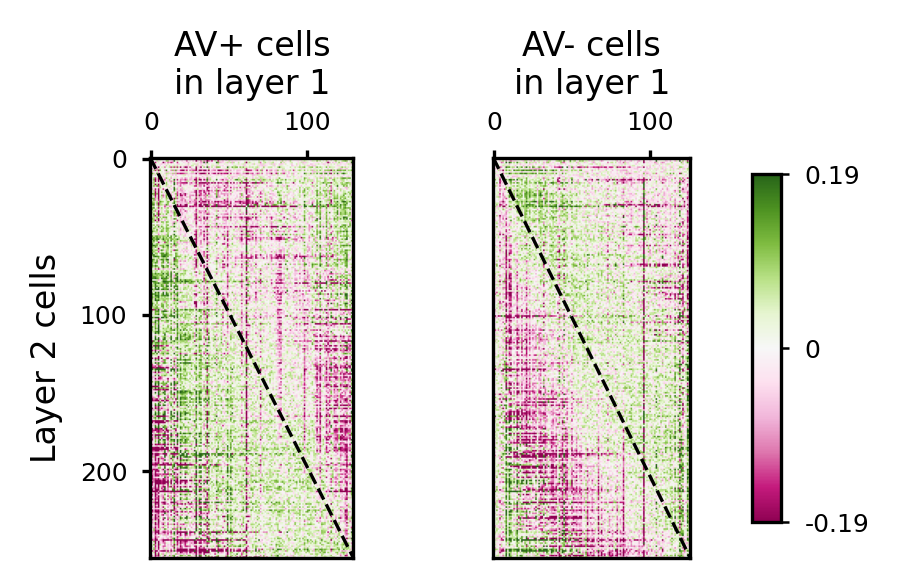

In [8]:

# ------------------------------------------------------
# LMN input weights
# ------------------------------------------------------
W_input = model.LmnRNN.weight_ih_l0.detach().cpu().numpy()   # [N_lmn, input_dim]

options.sequence_length = 100
options.batch_size = 100

model.eval()

# ------------------------------------------------------
# LMN
# ------------------------------------------------------
order_lmn = np.argsort(np.argmax(activations_lmn, axis=1))
W_lmn = model.LmnRNN.weight_hh_l0.detach().cpu().numpy()
eigs_lmn, _ = np.linalg.eig(W_lmn)
_, S_lmn, _ = np.linalg.svd(W_lmn)
W_lmn_sorted = W_lmn[order_lmn][:, order_lmn]
v_lmn = np.percentile(np.abs(W_lmn), 95)

# ------------------------------------------------------
# PaS
# Works for both:
# 1) vanilla nn.RNN  -> weight_hh_l0 / weight_ih_l0
# 2) adaptive RNN_adp -> J.weight / sensory_mapping.weight
# ------------------------------------------------------
order_pas = np.argsort(np.argmax(activations_pas, axis=1))

if hasattr(model.PaSRNN, "weight_hh_l0"):
    # vanilla nn.RNN
    W_pas = model.PaSRNN.weight_hh_l0.detach().cpu().numpy()
    lmn2pas = model.PaSRNN.weight_ih_l0.detach().cpu().numpy()
elif hasattr(model.PaSRNN, "J") and hasattr(model.PaSRNN, "sensory_mapping"):
    # adaptive PaS
    W_pas = model.PaSRNN.J.weight.detach().cpu().numpy()
    lmn2pas = model.PaSRNN.sensory_mapping.weight.detach().cpu().numpy()
else:
    raise AttributeError("Cannot find PaS recurrent/input weights on model.PaSRNN")

eigs_pas, _ = np.linalg.eig(W_pas)
_, S_pas, _ = np.linalg.svd(W_pas)
W_pas_sorted = W_pas[order_pas][:, order_pas]
v_pas = np.percentile(np.abs(W_pas), 95)

# LMN -> PaS feedforward matrix, reordered by preferred directions
W = lmn2pas[order_pas][:, order_lmn]

# ------------------------------------------------------
# split LMN columns of W by LMN input-weight sign
# ------------------------------------------------------
# if input dim = 1, this becomes one signed input weight per LMN cell
# if input dim > 1, use the mean signed input weight per cell
if W_input.ndim == 2 and W_input.shape[1] == 1:
    input_sign_value = W_input[:, 0]
else:
    input_sign_value = W_input.mean(axis=1)

# reorder into the same LMN column order used in W
input_sign_value_sorted = input_sign_value[order_lmn]

idx_pos  = np.where(input_sign_value_sorted > 0)[0]
idx_neg  = np.where(input_sign_value_sorted < 0)[0]
idx_zero = np.where(np.isclose(input_sign_value_sorted, 0.0))[0]

# split columns of the feedforward matrix W
W_pos = W[:, idx_pos]
W_neg = W[:, idx_neg]

print(f"# LMN cells with positive input weight: {len(idx_pos)}")
print(f"# LMN cells with negative input weight: {len(idx_neg)}")
print(f"# LMN cells with zero input weight: {len(idx_zero)}")

# ------------------------------------------------------
# plot
# ------------------------------------------------------
v = np.percentile(np.abs(W), 95)

fig, axs = plt.subplots(1, 2, figsize=(2.8, 2), dpi=300)
fig.subplots_adjust(wspace=0.3)

if W_pos.shape[1] > 0:
    im0 = axs[0].imshow(
        W_pos, cmap='PiYG', aspect='equal',
        origin='upper', vmin=-v, vmax=v
    )
else:
    im0 = None
    axs[0].text(
        0.5, 0.5, 'No cells',
        ha='center', va='center',
        transform=axs[0].transAxes
    )


axs[0].plot(
    [-0.5, W_pos.shape[1] - 0.5],
    [-0.5, W_pos.shape[0] - 0.5],
    color='black',
    linewidth=0.8,  
    linestyle='--',
)

axs[0].set_xlabel('AV+ cells\nin layer 1', fontsize=8)
axs[0].xaxis.set_label_position("top")
axs[0].xaxis.tick_top()
axs[0].set_ylabel('Layer 2 cells', fontsize=8)
axs[0].tick_params(axis='x', labelsize=6, top=True, bottom=False, length=2)
axs[0].tick_params(axis='y', labelsize=6, length=2)
#set y tick labels as 0,100, 200
axs[0].set_yticks([0, 100, 200])


if W_neg.shape[1] > 0:
    im1 = axs[1].imshow(
        W_neg, cmap='PiYG', aspect='equal',
        origin='upper', vmin=-v, vmax=v
    )
else:
    im1 = None
    axs[1].text(
        0.5, 0.5, 'No cells',
        ha='center', va='center',
        transform=axs[1].transAxes
    )
    
axs[1].plot(
    [-0.5, W_neg.shape[1] - 0.5],
    [-0.5, W_neg.shape[0] - 0.5],
    color='black',
    linewidth=0.8,
    linestyle='--',
)


axs[1].set_xlabel('AV- cells\nin layer 1', fontsize=8)
axs[1].xaxis.set_label_position("top")
axs[1].xaxis.tick_top()
axs[1].tick_params(axis='x', labelsize=6, top=True, bottom=False, length=2)
axs[1].tick_params(axis='y', labelsize=6)
#yticsk off
axs[1].set_yticks([])

fig.subplots_adjust(
    left=0.18,
    right=0.82,
    bottom=0.12,
    top=0.82,
    wspace=0.35,
)

mappable = im0 if im0 is not None else im1
if mappable is not None:
    cbar_ax = fig.add_axes([0.96, 0.12, 0.035, 0.58])
    cbar = fig.colorbar(mappable, cax=cbar_ax)

    cbar.set_ticks([-v, 0, v])
    cbar.set_ticklabels([f'{-v:.2f}', '0', f'{v:.2f}'])
    cbar.ax.tick_params(labelsize=6, length=2, width=0.6)

# 不要再用 tight_layout()


plt.tight_layout()

plt.savefig(
    "./docs/layer1to2_pas_feedforward_weights.pdf",
    bbox_inches="tight",
    pad_inches=0.03,
)


### Plot asymmetric connection from AHV+ to layer 2 and AHV- to layer 2 (Just a different way of visualisation)

In [9]:
import numpy as np
import matplotlib.pyplot as plt


def plot_topk_two_feedforward_to_center(
    W_pos,
    W_neg,
    title_pos="AHV+",
    title_mid="RNN\nlayer2",
    title_neg="AHV-",
    color_pos="#F18D00",
    color_neg="#009FB9",
    k=10,
    pre_start=0,
    pre_end_pos=None,
    pre_end_neg=None,
    post_start=0,
    post_end=None,
    n_pre_sample=50,
    n_post_sample=50,
):
    """
    W_pos[i, j] = AHV+ pre neuron j -> RNN layer2 post neuron i
    W_neg[i, j] = AHV- pre neuron j -> RNN layer2 post neuron i

    rows = post neurons, RNN layer2
    columns = pre neurons, AHV layer

    Draws one 3-layer plot:
        top    = AHV+
        middle = RNN layer2
        bottom = AHV-
    """

    assert W_pos.shape[0] == W_neg.shape[0], "W_pos and W_neg must have same post dimension"

    n_post_total = W_pos.shape[0]
    n_pre_pos_total = W_pos.shape[1]
    n_pre_neg_total = W_neg.shape[1]

    if pre_end_pos is None:
        pre_end_pos = n_pre_pos_total
    if pre_end_neg is None:
        pre_end_neg = n_pre_neg_total
    if post_end is None:
        post_end = n_post_total

    assert 0 <= pre_start < pre_end_pos <= n_pre_pos_total
    assert 0 <= pre_start < pre_end_neg <= n_pre_neg_total
    assert 0 <= post_start < post_end <= n_post_total

    def sample_evenly(start, end, n_sample):
        candidates = np.arange(start, end)
        n_sample = min(n_sample, len(candidates))
        sample_idx = np.linspace(
            0, len(candidates) - 1, n_sample
        ).round().astype(int)
        return candidates[sample_idx]

    post_neurons = sample_evenly(post_start, post_end, n_post_sample)
    pre_pos_neurons = sample_evenly(pre_start, pre_end_pos, n_pre_sample)
    pre_neg_neurons = sample_evenly(pre_start, pre_end_neg, n_pre_sample)

    W_pos_sub = W_pos[np.ix_(post_neurons, pre_pos_neurons)]
    W_neg_sub = W_neg[np.ix_(post_neurons, pre_neg_neurons)]

    n_post = len(post_neurons)
    n_pre_pos = len(pre_pos_neurons)
    n_pre_neg = len(pre_neg_neurons)

    k = min(k, n_post)

    def circular_mean_index(idxs, weights, n_units):
        angles = 2 * np.pi * np.asarray(idxs, dtype=float) / float(n_units)
        weights = np.asarray(weights, dtype=float)

        weights = np.maximum(weights, 0)

        total = np.sum(weights)
        if total <= 1e-8:
            return float(np.mean(idxs))

        x = np.sum(weights * np.cos(angles)) / total
        y = np.sum(weights * np.sin(angles)) / total

        avg_angle = np.arctan2(y, x) % (2 * np.pi)
        avg_idx = avg_angle / (2 * np.pi) * float(n_units)

        return avg_idx

    def draw_feedforward_arrows(
        ax,
        W_sub,
        y_pre,
        y_post,
        color,
        direction="down",
        draw_average=True,
    ):
        n_post, n_pre = W_sub.shape

        topk_post = np.argsort(W_sub, axis=0)[-k:, :]

        jmin = W_sub.min()
        jmax = W_sub.max()

        arrow_starts = []
        arrow_ends = []
        arrow_strengths = []

        for j in range(n_pre):
            top_idx = topk_post[:, j]
            top_w = W_sub[top_idx, j]

            avg_i = circular_mean_index(top_idx, top_w, n_post)
            avg_w = np.mean(top_w)

            strength = (avg_w - jmin) / (jmax - jmin + 1e-8)
            linewidth = 1
            alpha = 0.3

            if direction == "down":
                xytext = (j, y_pre - 0.03)
                xy = (avg_i, y_post + 0.03)
            else:
                xytext = (j, y_pre + 0.03)
                xy = (avg_i, y_post - 0.03)

            arrow_starts.append(xytext)
            arrow_ends.append(xy)
            arrow_strengths.append(strength)

            ax.annotate(
                "",
                xy=xy,
                xytext=xytext,
                arrowprops=dict(
                    arrowstyle="->",
                    color=color,
                    lw=linewidth,
                    alpha=alpha,
                    shrinkA=8,
                    shrinkB=8,
                ),
                zorder=1,
            )

        if draw_average and len(arrow_starts) > 0:
            arrow_starts = np.asarray(arrow_starts)
            arrow_ends = np.asarray(arrow_ends)
            arrow_strengths = np.asarray(arrow_strengths)

            avg_start_x = np.mean(arrow_starts[:, 0])
            avg_start_y = np.mean(arrow_starts[:, 1])

            avg_end_x = np.mean(arrow_ends[:, 0])
            avg_end_y = np.mean(arrow_ends[:, 1])

            avg_strength = np.mean(arrow_strengths)

            ax.annotate(
                "",
                xy=(avg_end_x, avg_end_y),
                xytext=(avg_start_x, avg_start_y),
                arrowprops=dict(
                    arrowstyle="->",
                    color=color,
                    lw=3.0,
                    alpha=0.95,
                    shrinkA=8,
                    shrinkB=8,
                    mutation_scale=16,
                ),
                zorder=4,
            )


    y_pos = 1.0
    y_mid = 0.0
    y_neg = -1.0

    fig, ax = plt.subplots(figsize=(3, 2), dpi=300)

    # neurons
    ax.scatter(
        np.arange(n_pre_pos),
        np.ones(n_pre_pos) * y_pos,
        s=120,
        facecolors=color_pos,
        edgecolors="black",
        zorder=3,
        alpha=0.5,
    )

    ax.scatter(
        np.arange(n_post),
        np.ones(n_post) * y_mid,
        s=120,
        facecolors="lightgray",
        edgecolors="black",
        zorder=3,
        alpha=0.5
    )

    ax.scatter(
        np.arange(n_pre_neg),
        np.ones(n_pre_neg) * y_neg,
        s=120,
        facecolors=color_neg,
        edgecolors="black",
        zorder=3,
        alpha=0.5,
    )

    # arrows
    draw_feedforward_arrows(
        ax,
        W_pos_sub,
        y_pre=y_pos,
        y_post=y_mid,
        color=color_pos,
        direction="down",
    )

    draw_feedforward_arrows(
        ax,
        W_neg_sub,
        y_pre=y_neg,
        y_post=y_mid,
        color=color_neg,
        direction="up",
    )

    # layer labels
    label_x = -8

    ax.text(
        label_x,
        y_pos,
        title_pos,
        ha="center",
        va="center",
        fontsize=8,
        color=color_pos,
    )

    ax.text(
        label_x,
        y_mid,
        title_mid,
        ha="center",
        va="center",
        fontsize=8,
        color="black",
    )

    ax.text(
        label_x,
        y_neg,
        title_neg,
        ha="center",
        va="center",
        fontsize=8,
        color=color_neg,
    )

    def add_angle_labels(y, n_units, above=True):
        dy = 0.13 if above else -0.13
        va = "bottom" if above else "top"

        ax.text(
            0,
            y + dy,
            "0°",
            ha="center",
            va=va,
            fontsize=7,
        )

        # ax.text(
        #     (n_units - 1) / 2,
        #     y + dy,
        #     "180°",
        #     ha="center",
        #     va=va,
        #     fontsize=7,
        # )

        ax.text(
            n_units - 1,
            y + dy,
            "360°",
            ha="center",
            va=va,
            fontsize=7,
        )

    add_angle_labels(y_pos, n_pre_pos, above=True)
    add_angle_labels(y_mid, n_post, above=True)
    add_angle_labels(y_neg, n_pre_neg, above=False)

    max_n = max(n_pre_pos, n_pre_neg, n_post)

    ax.set_xlim(-1, max_n)
    ax.set_ylim(-1.25, 1.25)
    ax.axis("off")

    plt.tight_layout()
    plt.savefig("./docs/layer1to2_lmn_pas_topk_feedforward.pdf", bbox_inches='tight')


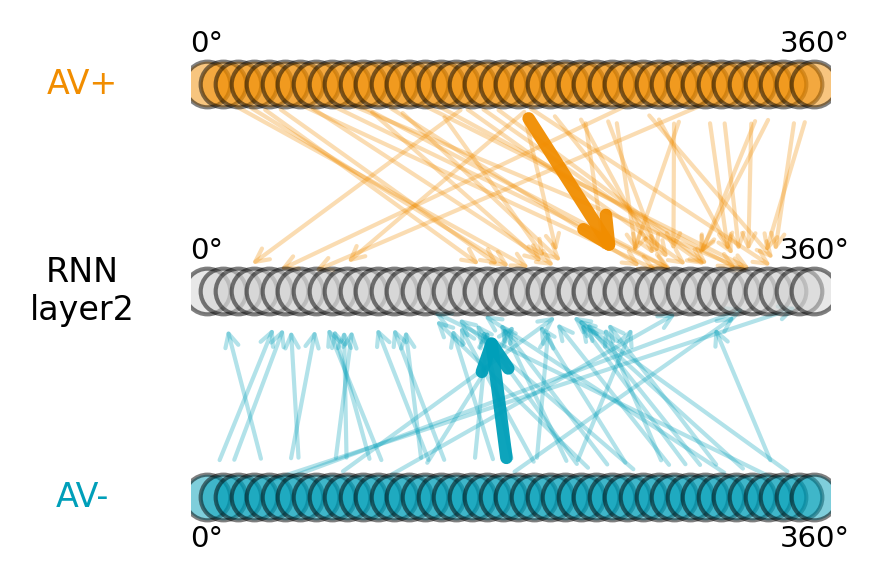

In [10]:
plot_topk_two_feedforward_to_center(
    W_pos,
    W_neg,
    title_pos="AV+",
    title_mid="RNN\nlayer2",
    title_neg="AV-",
    color_pos="#F18D00",
    color_neg="#009FB9",
    k=30,
    pre_start=20,
    pre_end_pos=W_pos.shape[1] - 20,
    pre_end_neg=W_neg.shape[1] - 20,
    post_start=0,
    post_end=W_pos.shape[0],
    n_pre_sample=40,
    n_post_sample=40,
)




### 6, visualise toroidal attractor in the mEC layer @HuiwenZhang00

In [11]:
#TBD

### 7, run cross correlation between layer 2 and layer 3 neurons and check the prefereed direction tuning (like Vollan paper Figure 3)

In [12]:
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scipy.ndimage import gaussian_filter1d
from scipy.signal import correlate
from tqdm import tqdm
import numpy as np


def compute_hd_tuning(activity, ang, n_bins=60, smooth_sigma=1.0):
    activity = np.asarray(activity, dtype=float)
    ang = np.asarray(ang, dtype=float).squeeze()

    if activity.ndim == 3:
        activity = activity.reshape(-1, activity.shape[-1])
    if ang.ndim == 2:
        ang = ang.reshape(-1)
    if ang.ndim == 3 and ang.shape[-1] == 1:
        ang = ang[..., 0].reshape(-1)

    ang = (ang + np.pi) % (2 * np.pi) - np.pi

    edges = np.linspace(-np.pi, np.pi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    bin_idx = np.digitize(ang, edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    tuning = np.zeros((activity.shape[1], n_bins), dtype=np.float32)
    for b in range(n_bins):
        m = bin_idx == b
        if np.any(m):
            tuning[:, b] = np.nanmean(activity[m], axis=0)

    if smooth_sigma is not None and smooth_sigma > 0:
        tuning = gaussian_filter1d(
            tuning,
            sigma=float(smooth_sigma),
            axis=1,
            mode="wrap",
        )

    return tuning, centers


def mean_vector_length(tuning, centers):
    tuning = np.maximum(np.asarray(tuning, dtype=float), 0)
    s = tuning.sum(axis=1)

    mvl = np.full(tuning.shape[0], np.nan)
    ok = s > 1e-12

    x = np.sum(tuning[ok] * np.cos(centers)[None, :], axis=1) / s[ok]
    y = np.sum(tuning[ok] * np.sin(centers)[None, :], axis=1) / s[ok]
    mvl[ok] = np.sqrt(x**2 + y**2)
    return mvl


def compute_directional_mvl(trace, ang, thr=1e-8, n_bins=60, smooth_sigma=1.0):
    trace = np.asarray(trace, dtype=float)

    if trace.ndim == 3:
        keep = np.max(np.abs(trace), axis=(0, 1)) > thr
        trace_ns = trace[..., keep].reshape(-1, keep.sum())
    else:
        keep = np.max(np.abs(trace), axis=0) > thr
        trace_ns = trace[:, keep]

    tuning, centers = compute_hd_tuning(
        trace_ns,
        ang,
        n_bins=n_bins,
        smooth_sigma=smooth_sigma,
    )
    directional_mvl = mean_vector_length(tuning, centers)
    return directional_mvl, keep


def zscore_cells(activity):
    activity = np.asarray(activity, dtype=float)
    mean = activity.mean(axis=0, keepdims=True)
    std = activity.std(axis=0, keepdims=True)

    ok = std.reshape(-1) > 1e-12
    activity_z = np.zeros_like(activity, dtype=float)
    activity_z[:, ok] = (activity[:, ok] - mean[:, ok]) / std[:, ok]
    return activity_z, ok


def find_zero_lag_pas_conj_pairs(
    pas,
    conj,
    conj_ids,
    lag_window=5,
    corr_threshold=0.2,
):
    pas = np.asarray(pas, dtype=float)
    conj = np.asarray(conj, dtype=float)

    T = pas.shape[0]
    lag_window = min(lag_window, T - 1)

    pas_z, pas_ok = zscore_cells(pas)
    conj_z, conj_ok = zscore_cells(conj)

    lags = np.arange(-T + 1, T)
    lag0_idx = np.where(lags == 0)[0][0]
    lo = lag0_idx - lag_window
    hi = lag0_idx + lag_window + 1

    valid_pas_ids = []
    valid_conj_ids = []
    valid_corr0 = []

    for p_id in tqdm(range(pas.shape[1]), desc="PaS-Conj zero-lag pairs"):
        if not pas_ok[p_id]:
            continue

        r_pas = pas_z[:, p_id]

        for c_id in conj_ids:
            if not conj_ok[c_id]:
                continue

            r_conj = conj_z[:, c_id]
            corr = correlate(r_conj, r_pas, mode="full") / T

            window = corr[lo:hi]
            peak_idx = np.argmax(window)
            corr0 = corr[lag0_idx]

            if peak_idx == lag_window and corr0 > corr_threshold:
                valid_pas_ids.append(p_id)
                valid_conj_ids.append(c_id)
                valid_corr0.append(corr0)

    return {
        "pas_ids": np.asarray(valid_pas_ids),
        "conj_ids": np.asarray(valid_conj_ids),
        "corr0": np.asarray(valid_corr0),
    }



In [14]:

# --------------------------------------------------
# settings
# --------------------------------------------------
options.sequence_length = 100
options.batch_size = 50
model.eval()

n_bins = 60
smooth_sigma = 1.0
mvl_thr = 0.5
corr_threshold = 0.2
lag_window = 5


# --------------------------------------------------
# compute activities
# --------------------------------------------------
# The four-layer ratemap function needs speed and initial place-cell activity.
# Cell 3 uses a direction-only generator for the LMN/PaS analysis, so rebuild
# the generator here with place cells before evaluating Conj and mEC.
trajectory_generator = TrajectoryGenerator(
    options, direction_cells=direction_cells, place_cells=place_cells
)
results = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    res_pos=20,
    n_avg=10,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

# returned tuple:
# 0-15  = directional/spatial activations and ratemaps
# 16    = lmn
# 17    = pas
# 18    = conj
# 19    = mec
# 20    = ang
# 21    = pos
(
    activations_lmn_dir,
    rate_map_lmn_dir,
    activations_pas_dir,
    rate_map_pas_dir,
    activations_conj_dir,
    rate_map_conj_dir,
    activations_mec_dir,
    rate_map_mec_dir,
    activations_lmn_spatial,
    rate_map_lmn_spatial,
    activations_pas_spatial,
    rate_map_pas_spatial,
    activations_conj_spatial,
    rate_map_conj_spatial,
    activations_mec_spatial,
    rate_map_mec_spatial,
    lmn,
    pas,
    conj,
    mec,
    ang,
    pos,
) = results


# --------------------------------------------------
# compute directional MVL
# --------------------------------------------------
conj_directional_mvl, conj_keep = compute_directional_mvl(
    conj,
    ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

mec_directional_mvl, mec_keep = compute_directional_mvl(
    mec,
    ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

print("conj_directional_mvl shape:", conj_directional_mvl.shape)
print("mec_directional_mvl shape:", mec_directional_mvl.shape)
print("non-silent Conj cells:", conj_keep.sum())
print("non-silent mEC cells:", mec_keep.sum())


# --------------------------------------------------
# select high-MVL Conj cells and find functional pairs
# --------------------------------------------------
conj_orig_ids_ns = np.where(conj_keep)[0]
conj_layer_hd_ids = conj_orig_ids_ns[conj_directional_mvl > mvl_thr]

print(
    f"Conj cells with MVL > {mvl_thr}: "
    f"{len(conj_layer_hd_ids)} / {len(conj_orig_ids_ns)} non-silent Conj cells"
)

pair_results = find_zero_lag_pas_conj_pairs(
    pas=pas,
    conj=conj,
    conj_ids=conj_layer_hd_ids,
    lag_window=lag_window,
    corr_threshold=corr_threshold,
)

print(f"Zero-lag PaS-Conj functional pairs: {len(pair_results['pas_ids'])}")


conj_directional_mvl shape: (311,)
mec_directional_mvl shape: (460,)
non-silent Conj cells: 311
non-silent mEC cells: 460
Conj cells with MVL > 0.5: 101 / 311 non-silent Conj cells


PaS-Conj zero-lag pairs: 100%|██████████| 256/256 [00:57<00:00,  4.43it/s]

Zero-lag PaS-Conj functional pairs: 7522


Zero-lag pairs, N=7522


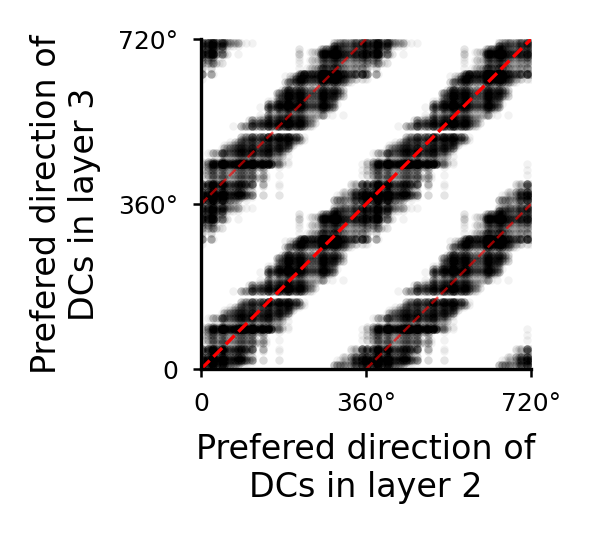

In [15]:
def preferred_direction_from_tuning(tuning, centers):
    pref_idx = np.argmax(tuning, axis=1)
    return centers[pref_idx]


def style_small_axis(ax):
    ax.tick_params(axis="both", labelsize=6, length=2, width=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_pd_alignment_two_cycles(conj_pair_pd, pas_pair_pd, save_path=None):
    # map from [-pi, pi] to [0, 2pi)
    conj0 = (np.asarray(conj_pair_pd) + 2 * np.pi) % (2 * np.pi)
    pas0 = (np.asarray(pas_pair_pd) + 2 * np.pi) % (2 * np.pi)

    xs = []
    ys = []

    for dx in [0, 2 * np.pi]:
        for dy in [0, 2 * np.pi]:
            xs.append(pas0 + dx)    # x axis = PaS
            ys.append(conj0 + dy)   # y axis = Conj

    x = np.concatenate(xs)
    y = np.concatenate(ys)

    fig, ax = plt.subplots(figsize=(2.0, 2.0), dpi=300)

    ax.scatter(
        x,
        y,
        s=4,
        color="black",
        alpha=0.05,
        linewidth=0,
    )

    ax.plot([0, 4*np.pi], [0, 4*np.pi], color="red", linestyle="--", linewidth=0.8)
    ax.plot([0, 2*np.pi], [2*np.pi, 4*np.pi], color="red", linestyle="--", linewidth=0.6, alpha=0.6)
    ax.plot([2*np.pi, 4*np.pi], [0, 2*np.pi], color="red", linestyle="--", linewidth=0.6, alpha=0.6)

    ax.set_xlim(0, 4 * np.pi)
    ax.set_ylim(0, 4 * np.pi)

    ax.set_xticks([0, 2 * np.pi, 4 * np.pi])
    ax.set_xticklabels(["0", "360°", "720°"])
    ax.set_yticks([0, 2 * np.pi, 4 * np.pi])
    ax.set_yticklabels(["0", "360°", "720°"])

    ax.set_xlabel("Prefered direction of\nDCs in layer 2", fontsize=8)
    ax.set_ylabel("Prefered direction of\nDCs in layer 3", fontsize=8)

    ax.set_aspect("equal")
    style_small_axis(ax)
    plt.tight_layout()

    print(f"Zero-lag pairs, N={len(conj_pair_pd)}")

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.03)

    plt.show()


# --------------------------------------------------
# compute preferred directions for all PaS and Conj cells
# --------------------------------------------------
pas_tuning, hd_centers = compute_hd_tuning(
    pas,
    ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

conj_tuning_all, _ = compute_hd_tuning(
    conj,
    ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

pas_pd = preferred_direction_from_tuning(pas_tuning, hd_centers)
conj_pd = preferred_direction_from_tuning(conj_tuning_all, hd_centers)


# --------------------------------------------------
# get preferred directions for functional pairs
# --------------------------------------------------
pas_pair_pd = pas_pd[pair_results["pas_ids"]]
conj_pair_pd = conj_pd[pair_results["conj_ids"]]


# --------------------------------------------------
# plot
# --------------------------------------------------
plot_pd_alignment_two_cycles(
    conj_pair_pd,
    pas_pair_pd,
    save_path="./docs/layer2to3_DC_connection_stats.pdf",
)


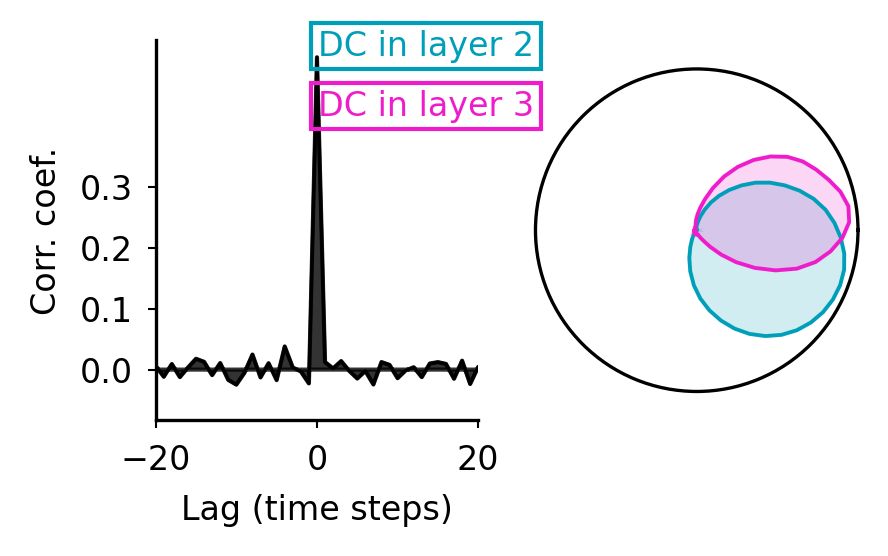

In [16]:
def normalize_tuning(x):
    x = np.asarray(x, dtype=float)
    x = np.maximum(x, 0)
    return x / (np.nanmax(x) + 1e-8)


def compute_pair_crosscorr(r_pas, r_conj):
    r_pas = np.asarray(r_pas)
    r_conj = np.asarray(r_conj)

    pas_std = r_pas.std()
    conj_std = r_conj.std()

    if pas_std <= 1e-12 or conj_std <= 1e-12:
        return None, None

    r_pas_z = (r_pas - r_pas.mean()) / pas_std
    r_conj_z = (r_conj - r_conj.mean()) / conj_std

    T = len(r_pas_z)
    corr = correlate(r_conj_z, r_pas_z, mode="full") / T
    lags = np.arange(-T + 1, T)
    return lags, corr


def plot_one_pas_conj_pair_overlay(
    pair_results,
    pas,
    conj,
    pas_tuning,
    conj_tuning_all,
    hd_centers,
    pair_idx=None,
    save_path=None,
):
    pas_ids = np.asarray(pair_results["pas_ids"])
    conj_ids = np.asarray(pair_results["conj_ids"])
    corr0_vals = np.asarray(pair_results["corr0"])

    n_pairs = len(pas_ids)
    if n_pairs == 0:
        print("No zero-lag PaS-Conj pairs found.")
        return

    if pair_idx is None:
        rng = np.random.default_rng(123)
        pair_idx = rng.choice(n_pairs)

    p_id = pas_ids[pair_idx]
    c_id = conj_ids[pair_idx]

    theta = np.concatenate([hd_centers, hd_centers[:1]])

    fig, axs = plt.subplots(1, 2, figsize=(3.0, 2.0), dpi=300)

    # 1) cross-correlation
    ax_corr = axs[0]
    lags, corr = compute_pair_crosscorr(pas[:, p_id], conj[:, c_id])

    if lags is not None:
        ax_corr.plot(lags, corr, color="black", linewidth=0.8)
        ax_corr.fill_between(
            lags, corr, 0,
            color="black",
            alpha=0.8,
            rasterized=True,
        )
        lag_lim = min(20, np.max(np.abs(lags)))
        ax_corr.set_xlim(-lag_lim, lag_lim)
    else:
        ax_corr.text(
            0.5, 0.5, "flat trace",
            ha="center",
            va="center",
            transform=ax_corr.transAxes,
            fontsize=7,
        )

    ax_corr.tick_params(axis="both", labelsize=8, length=2, width=0.5)
    ax_corr.spines["top"].set_visible(False)
    ax_corr.spines["right"].set_visible(False)
    ax_corr.set_xlabel("Lag (time steps)", fontsize=8)
    ax_corr.set_ylabel("Corr. coef.", fontsize=8)
    ax_corr.set_yticks([0, 0.1, 0.2, 0.3])

    # 2) overlay directional tuning
    axs[1].remove()
    ax_dir = fig.add_subplot(1, 2, 2, projection="polar")

    pas_vals = normalize_tuning(pas_tuning[p_id])
    conj_vals = normalize_tuning(conj_tuning_all[c_id])

    pas_vals = np.concatenate([pas_vals, pas_vals[:1]])
    conj_vals = np.concatenate([conj_vals, conj_vals[:1]])

    ax_dir.plot(theta, pas_vals, color="#009FB9", linewidth=0.9)
    ax_dir.fill(theta, pas_vals, color="#009FB9", alpha=0.18)

    ax_dir.plot(theta, conj_vals, color="#EE1CCB", linewidth=0.9)
    ax_dir.fill(theta, conj_vals, color="#EE1CCB", alpha=0.18)

    ax_dir.set_ylim(0, 1.05)
    ax_dir.set_xticks([])
    ax_dir.set_yticks([])

    fig.text(
        0.48, 0.86, "DC in layer 2",
        ha="center", va="center",
        fontsize=8, color="#009FB9",
        bbox=dict(
            boxstyle="square,pad=0.2",
            facecolor="none",
            edgecolor="#009FB9",
            linewidth=1,
        ),
    )

    fig.text(
        0.48, 0.76, "DC in layer 3",
        ha="center", va="center",
        fontsize=8, color="#EE1CCB",
        bbox=dict(
            boxstyle="square,pad=0.2",
            facecolor="none",
            edgecolor="#EE1CCB",
            linewidth=1,
        ),
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.03,
        )

    plt.show()


plot_one_pas_conj_pair_overlay(
    pair_results=pair_results,
    pas=pas,
    conj=conj,
    pas_tuning=pas_tuning,
    conj_tuning_all=conj_tuning_all,
    hd_centers=hd_centers,
    pair_idx=None,  # None = random one example
    save_path="./docs/layer2to3_DC_connection_example.pdf",
)


## Layer 3 to layer 4 spatial connection

Conj maps: (512, 20, 20)
mEC maps:  (512, 20, 20)
mECRNN input weight shape: (512, 512)
Convention: W_conj_to_mec[target_mEC_id, source_Conj_id]
High-HD Conj cells: 103 / 311 (MVL > 0.5)
Plotting 30 Conj source cells




In [17]:
# ============================================================
# Signed Conj->mEC weighted relative spatial CoM analysis
# 4-layer model version
#
# FROM = high-HD Conj cells
# TO   = all mEC cells
#
# Column 1: Conj HD tuning
# Column 2: Conj spatial map + own CoM
# Column 3: all mEC CoMs weighted by Conj->mEC input weights
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from visualize import compute_ratemaps_lmn_pas_conj_mec


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
hd_mvl_thr = 0.5
n_examples = 30

signed_norm_mode = "abs"   # "abs" or "sum"
pref_arrow_len_bins = 3.0

n_bins = 60
smooth_sigma = 1.0
eps = 1e-12

options.sequence_length = 100
options.batch_size = 200
model.eval()


# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def spatial_center_of_mass_2d(rmap, eps=1e-12):
    r = np.asarray(rmap, dtype=float)

    if not np.all(np.isfinite(r)):
        r = np.nan_to_num(r, nan=0.0, posinf=0.0, neginf=0.0)

    r = r - np.nanmin(r)
    r[r < 0] = 0

    mass = np.nansum(r)
    if mass <= eps:
        return np.nan, np.nan

    H, W = r.shape
    yy, xx = np.mgrid[0:H, 0:W]

    x_com = np.nansum(xx * r) / mass
    y_com = np.nansum(yy * r) / mass
    return x_com, y_com


def compute_all_spatial_coms(rate_maps_3d):
    rate_maps_3d = np.asarray(rate_maps_3d)
    com_xy = np.full((rate_maps_3d.shape[0], 2), np.nan, dtype=float)

    for i in range(rate_maps_3d.shape[0]):
        com_xy[i] = spatial_center_of_mass_2d(rate_maps_3d[i])

    return com_xy


def normalize_1d(x, eps=1e-12):
    x = np.asarray(x, dtype=float)

    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    xmin = np.min(x)
    xmax = np.max(x)

    if xmax - xmin <= eps:
        return np.zeros_like(x)

    return (x - xmin) / (xmax - xmin)


def compute_hd_tuning(trace, ang, n_bins=60, smooth_sigma=None):
    trace = np.asarray(trace, dtype=float)
    ang = np.asarray(ang, dtype=float).squeeze()

    if trace.ndim == 3:
        trace = trace.reshape(-1, trace.shape[-1])

    if ang.ndim == 2:
        ang = ang.reshape(-1)
    if ang.ndim == 3 and ang.shape[-1] == 1:
        ang = ang[..., 0].reshape(-1)

    assert trace.shape[0] == ang.shape[0], (
        f"trace time length {trace.shape[0]} does not match ang length {ang.shape[0]}"
    )

    ang = (ang + np.pi) % (2 * np.pi) - np.pi

    edges = np.linspace(-np.pi, np.pi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    bin_idx = np.digitize(ang, edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    tuning = np.zeros((trace.shape[1], n_bins), dtype=np.float32)
    for b in range(n_bins):
        m = bin_idx == b
        if np.any(m):
            tuning[:, b] = np.nanmean(trace[m], axis=0)

    if smooth_sigma is not None and smooth_sigma > 0:
        tuning = gaussian_filter1d(
            tuning,
            sigma=float(smooth_sigma),
            axis=1,
            mode="wrap",
        )

    return tuning, centers


def signed_weighted_relative_com(
    source_com,
    target_coms,
    signed_weights,
    norm_mode="abs",
    eps=1e-12,
    clip_to_bounds=None,
):
    source_com = np.asarray(source_com, dtype=float)
    target_coms = np.asarray(target_coms, dtype=float)
    signed_weights = np.asarray(signed_weights, dtype=float)

    valid = (
        np.isfinite(signed_weights)
        & np.isfinite(target_coms[:, 0])
        & np.isfinite(target_coms[:, 1])
        & np.isfinite(source_com[0])
        & np.isfinite(source_com[1])
        & (np.abs(signed_weights) > eps)
    )

    if valid.sum() == 0:
        return np.nan, np.nan, valid

    wv = signed_weights[valid]
    xyv = target_coms[valid]
    dxy = xyv - source_com[None, :]

    if norm_mode == "abs":
        denom = np.sum(np.abs(wv))
    elif norm_mode == "sum":
        denom = np.sum(wv)
    else:
        raise ValueError("norm_mode must be 'abs' or 'sum'")

    if np.abs(denom) <= eps:
        return np.nan, np.nan, valid

    dxy_pop = np.sum(wv[:, None] * dxy, axis=0) / denom
    x_pop = source_com[0] + dxy_pop[0]
    y_pop = source_com[1] + dxy_pop[1]

    if clip_to_bounds is not None:
        H, W = clip_to_bounds
        x_pop = np.clip(x_pop, -0.5, W - 0.5)
        y_pop = np.clip(y_pop, -0.5, H - 0.5)

    return x_pop, y_pop, valid


def ensure_3d_rate_maps(rate_maps, res_pos):
    rate_maps = np.asarray(rate_maps)

    if rate_maps.ndim == 3:
        return rate_maps

    if rate_maps.ndim == 2:
        assert rate_maps.shape[1] == res_pos * res_pos, (
            f"2D rate map shape {rate_maps.shape} incompatible with res_pos={res_pos}"
        )
        return rate_maps.reshape(rate_maps.shape[0], res_pos, res_pos)

    raise ValueError(f"Unsupported ratemap shape: {rate_maps.shape}")


# ------------------------------------------------------------
# Compute activities
# ------------------------------------------------------------
# Ensure this standalone four-layer analysis has place-cell initial states.
trajectory_generator = TrajectoryGenerator(
    options, direction_cells=direction_cells, place_cells=place_cells
)
results = compute_ratemaps_lmn_pas_conj_mec(
    model,
    trajectory_generator,
    options,
    res=60,
    res_pos=20,
    n_avg=10,
    N_lmn=options.Nlmn,
    N_pas=options.Npas,
    N_conj=options.Ncg,
    N_mec=options.Ng,
)

(
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    _,
    activations_conj_spatial,
    rate_map_conj_spatial,
    activations_mec_spatial,
    rate_map_mec_spatial,
    _,
    _,
    conj,
    _,
    ang,
    _,
) = results


# ------------------------------------------------------------
# Prepare ratemaps and CoMs
# ------------------------------------------------------------
res_pos = activations_conj_spatial.shape[-1]

conj_maps_all = ensure_3d_rate_maps(rate_map_conj_spatial, res_pos)
mec_maps_all = ensure_3d_rate_maps(rate_map_mec_spatial, res_pos)

# Match plotting convention used elsewhere
conj_maps_plot_all = np.asarray([rm.T for rm in conj_maps_all])
mec_maps_plot_all = np.asarray([rm.T for rm in mec_maps_all])

N_conj, H, W_map = conj_maps_plot_all.shape
N_mec = mec_maps_plot_all.shape[0]

conj_com_xy_all = compute_all_spatial_coms(conj_maps_plot_all)
mec_com_xy_all = compute_all_spatial_coms(mec_maps_plot_all)

print(f"Conj maps: {conj_maps_plot_all.shape}")
print(f"mEC maps:  {mec_maps_plot_all.shape}")


# ------------------------------------------------------------
# Prepare HD tuning
# ------------------------------------------------------------
conj_tuning_all, centers = compute_hd_tuning(
    trace=conj,
    ang=ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

assert conj_tuning_all.shape[0] == N_conj, (
    f"conj_tuning_all has {conj_tuning_all.shape[0]} cells, but N_conj={N_conj}"
)

theta = np.concatenate([centers, centers[:1]])


# ------------------------------------------------------------
# Prepare non-silent indexing
# Requires existing:
#   conj_grid_score
#   conj_directional_mvl
#   conj_keep
# ------------------------------------------------------------
conj_directional_mvl, conj_keep = compute_directional_mvl(
    conj,
    ang,
    n_bins=n_bins,
    smooth_sigma=smooth_sigma,
)

conj_directional_mvl = np.asarray(conj_directional_mvl)
conj_keep = np.asarray(conj_keep).astype(bool)

conj_orig_ids_ns = np.where(conj_keep)[0]
N_conj_keep = len(conj_orig_ids_ns)

assert conj_directional_mvl.shape[0] == N_conj_keep
assert np.max(conj_orig_ids_ns) < N_conj


# ------------------------------------------------------------
# Get Conj -> mEC weights
# ------------------------------------------------------------
W_conj_to_mec = model.mECRNN.weight_ih_l0.detach().cpu().numpy()

assert W_conj_to_mec.shape[0] == N_mec
assert W_conj_to_mec.shape[1] == N_conj

print(f"mECRNN input weight shape: {W_conj_to_mec.shape}")
print("Convention: W_conj_to_mec[target_mEC_id, source_Conj_id]")


# ------------------------------------------------------------
# Select high-HD Conj cells
# ------------------------------------------------------------
high_hd_local_ns_ids = np.where(
    (conj_directional_mvl > hd_mvl_thr)
)[0]

high_hd_local_ns_ids = high_hd_local_ns_ids[
    np.argsort(-conj_directional_mvl[high_hd_local_ns_ids])
]

show_local_ns_ids = high_hd_local_ns_ids[:min(n_examples, len(high_hd_local_ns_ids))]

print(
    f"High-HD Conj cells: {len(high_hd_local_ns_ids)} / {N_conj_keep} "
    f"(MVL > {hd_mvl_thr})"
)
print(f"Plotting {len(show_local_ns_ids)} Conj source cells")


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
if len(show_local_ns_ids) == 0:
    print("No high-HD Conj cells found. Try lowering hd_mvl_thr or increasing grid_thr.")
else:
    fig = plt.figure(figsize=(7.5, 2.1 * len(show_local_ns_ids)), dpi=300)

    target_mec_ids = np.arange(N_mec)
    target_mec_coms = mec_com_xy_all[target_mec_ids]

    for row, conj_local_ns in enumerate(show_local_ns_ids):
        conj_orig = conj_orig_ids_ns[conj_local_ns]

        x_conj, y_conj = conj_com_xy_all[conj_orig]
        pref_ang = centers[np.argmax(conj_tuning_all[conj_orig])]

        signed_weights_mec = W_conj_to_mec[target_mec_ids, conj_orig]

        x_pop, y_pop, valid_mec = signed_weighted_relative_com(
            source_com=conj_com_xy_all[conj_orig],
            target_coms=target_mec_coms,
            signed_weights=signed_weights_mec,
            norm_mode=signed_norm_mode,
            eps=eps,
            clip_to_bounds=(H, W_map),
        )

        plot_coms = target_mec_coms[valid_mec]
        plot_w = signed_weights_mec[valid_mec]

        pos_mask = plot_w > 0
        neg_mask = plot_w < 0

        if len(plot_w) > 0:
            abs_w = np.abs(plot_w)
            abs_w_norm = abs_w / (np.nanmax(abs_w) + eps)
            sizes = 5 + 55 * abs_w_norm
            alphas = 0.12 + 0.75 * abs_w_norm
        else:
            sizes = np.array([])
            alphas = np.array([])

        # Column 1: directional tuning
        ax_dir = fig.add_subplot(len(show_local_ns_ids), 3, row * 3 + 1, projection="polar")

        tuning = normalize_1d(conj_tuning_all[conj_orig])
        tuning_closed = np.concatenate([tuning, tuning[:1]])

        ax_dir.plot(theta, tuning_closed, color="grey", linewidth=1.0)
        ax_dir.fill(theta, tuning_closed, color="grey", alpha=0.20)
        ax_dir.plot(
            [pref_ang, pref_ang],
            [0, 1.05],
            color="black",
            linewidth=0.8,
            linestyle="--",
        )

        ax_dir.set_ylim(0, 1.1)
        ax_dir.set_xticks([])
        ax_dir.set_yticks([])
        ax_dir.set_title(
            f"Conj ns {conj_local_ns}, orig {conj_orig}\n"
            f"MVL={conj_directional_mvl[conj_local_ns]:.2f}, ",
            fontsize=8,
        )

        # Column 2: Conj map + own CoM
        ax_map = fig.add_subplot(len(show_local_ns_ids), 3, row * 3 + 2)
        ax_map.imshow(conj_maps_plot_all[conj_orig], origin="lower", aspect="equal", cmap="jet")
        ax_map.scatter(
            [x_conj], [y_conj],
            s=40,
            color="white",
            edgecolor="black",
            linewidth=0.7,
            zorder=5,
        )
        ax_map.set_xticks([])
        ax_map.set_yticks([])
        ax_map.set_title("Conj spatial map + own CoM", fontsize=8)

        # Column 3: weighted mEC CoM summary
        ax_pop = fig.add_subplot(len(show_local_ns_ids), 3, row * 3 + 3)
        ax_pop.imshow(
            conj_maps_plot_all[conj_orig],
            origin="lower",
            aspect="equal",
            cmap="Greys",
            alpha=0.22,
        )

        if np.any(pos_mask):
            ax_pop.scatter(
                plot_coms[pos_mask, 0],
                plot_coms[pos_mask, 1],
                s=sizes[pos_mask],
                color="#D62728",
                alpha=alphas[pos_mask],
                edgecolor="none",
                zorder=3,
            )

        if np.any(neg_mask):
            ax_pop.scatter(
                plot_coms[neg_mask, 0],
                plot_coms[neg_mask, 1],
                s=sizes[neg_mask],
                color="#1F77B4",
                alpha=alphas[neg_mask],
                edgecolor="none",
                zorder=3,
            )

        ax_pop.scatter(
            [x_conj], [y_conj],
            s=50,
            color="#EE1CCB",
            edgecolor="black",
            linewidth=0.7,
            zorder=7,
        )

        ax_pop.scatter(
            [x_pop], [y_pop],
            s=75,
            color="yellow",
            edgecolor="black",
            linewidth=0.8,
            zorder=8,
        )

        if (
            np.isfinite(x_conj)
            and np.isfinite(y_conj)
            and np.isfinite(x_pop)
            and np.isfinite(y_pop)
        ):
            dx = x_pop - x_conj
            dy = y_pop - y_conj

            ax_pop.arrow(
                x_conj,
                y_conj,
                dx,
                dy,
                color="black",
                width=0.03,
                head_width=0.6,
                head_length=0.7,
                length_includes_head=True,
                zorder=9,
            )

            angle = np.arctan2(dy, dx)
            ax_pop.text(
                x_pop,
                y_pop,
                f"{angle:.2f}",
                fontsize=6,
                color="black",
                ha="left",
                va="bottom",
                zorder=10,
            )

        if np.isfinite(x_conj) and np.isfinite(y_conj) and np.isfinite(pref_ang):
            dx_pref = pref_arrow_len_bins * np.cos(pref_ang)
            dy_pref = pref_arrow_len_bins * np.sin(pref_ang)

            ax_pop.arrow(
                x_conj,
                y_conj,
                dx_pref,
                dy_pref,
                color="#AA00AA",
                width=0.025,
                head_width=0.55,
                head_length=0.65,
                length_includes_head=True,
                zorder=10,
            )

            ax_pop.text(
                x_conj + dx_pref,
                y_conj + dy_pref,
                f"pref {pref_ang:.2f}",
                fontsize=6,
                color="#AA00AA",
                ha="right",
                va="top",
                zorder=11,
            )

        ax_pop.set_xlim(-0.5, W_map - 0.5)
        ax_pop.set_ylim(-0.5, H - 0.5)
        ax_pop.set_xticks([])
        ax_pop.set_yticks([])

        n_pos = np.sum(plot_w > 0)
        n_neg = np.sum(plot_w < 0)

        ax_pop.set_title(
            f"Conj->mEC signed weighted CoM\n+:{n_pos}, -:{n_neg}",
            fontsize=8,
        )

    fig.text(
        0.70, 0.985,
        "red = positive Conj->mEC input weight",
        ha="center", va="top", fontsize=8, color="#D62728",
    )
    fig.text(
        0.70, 0.965,
        "blue = negative Conj->mEC input weight",
        ha="center", va="top", fontsize=8, color="#1F77B4",
    )
    fig.text(
        0.70, 0.945,
        "black arrow = Conj HD CoM -> signed weighted mEC CoM; purple arrow = Conj HD preferred direction",
        ha="center", va="top", fontsize=8, color="black",
    )
    fig.text(
        0.70, 0.925,
        (
            f"weighted CoM = Conj CoM + sum(w·(mEC CoM − Conj CoM)) / "
            f"sum({('|w|' if signed_norm_mode == 'abs' else 'w')}); "
            f"W = mECRNN.weight_ih_l0[target_mEC, source_Conj]"
        ),
        ha="center", va="top", fontsize=8, color="black",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()


Plotting specified Conj ns cells: [11, 113, 282, 251]
Conj ns 11, orig 19, MVL=0.817, pref=0.471
Conj ns 113, orig 174, MVL=0.845, pref=-2.461
Conj ns 282, orig 463, MVL=0.819, pref=-0.890
Conj ns 251, orig 412, MVL=0.786, pref=2.251


/tmp/ipykernel_515487/1467184196.py:73: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


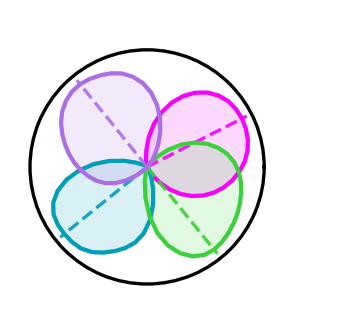

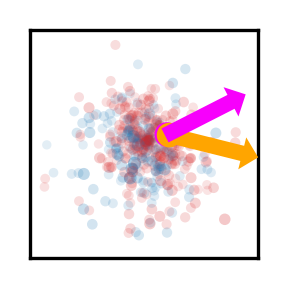

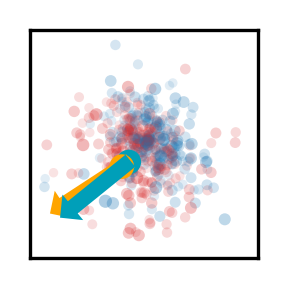

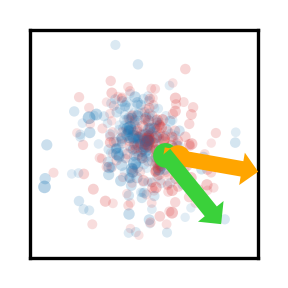

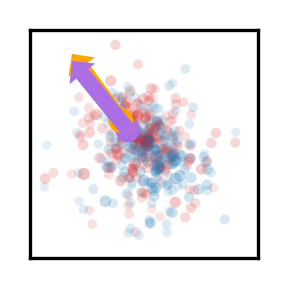

In [18]:
# ------------------------------------------------------------
# Select specific Conj ns cells manually
# ------------------------------------------------------------
selected_local_ns_ids = np.array([11, 113, 282, 251], dtype=int)

valid_selected = selected_local_ns_ids[
    (selected_local_ns_ids >= 0) & (selected_local_ns_ids < N_conj_keep)
]

if len(valid_selected) < len(selected_local_ns_ids):
    missing = sorted(set(selected_local_ns_ids.tolist()) - set(valid_selected.tolist()))
    print(f"These Conj ns ids are out of range and will be skipped: {missing}")

show_local_ns_ids = valid_selected[:4]

print(f"Plotting specified Conj ns cells: {show_local_ns_ids.tolist()}")


# ------------------------------------------------------------
# Plot all 4 directional tunings on one polar axis
# ------------------------------------------------------------
if len(show_local_ns_ids) == 0:
    print("No valid Conj ns cells to plot.")
else:
    colors = ["#F700FC", "#009FB9", "#3AD13A", "#AC6EE5"]

    fig, ax = plt.subplots(
        figsize=(1.2, 1.2),
        dpi=300,
        subplot_kw={"projection": "polar"},
    )

    for i, conj_local_ns in enumerate(show_local_ns_ids):
        conj_orig = conj_orig_ids_ns[conj_local_ns]

        tuning = normalize_1d(conj_tuning_all[conj_orig])
        tuning_closed = np.concatenate([tuning, tuning[:1]])

        pref_ang = centers[np.argmax(conj_tuning_all[conj_orig])]
        color = colors[i % len(colors)]

        ax.plot(
            theta,
            tuning_closed,
            color=color,
            linewidth=1.0,
        )
        ax.fill(
            theta,
            tuning_closed,
            color=color,
            alpha=0.15,
        )
        ax.plot(
            [pref_ang, pref_ang],
            [0, 1.05],
            color=color,
            linewidth=0.8,
            linestyle="--",
            alpha=0.9,
        )

        print(
            f"Conj ns {conj_local_ns}, orig {conj_orig}, "
            f"MVL={conj_directional_mvl[conj_local_ns]:.3f}, "
            f"pref={pref_ang:.3f}"
        )

    ax.set_ylim(0, 1.1)
    ax.set_xticks([])
    ax.set_yticks([])

    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.25, 1.15),
        fontsize=7,
        frameon=False,
    )

    
    plt.tight_layout()
    plt.savefig(
        f"./docs/layer3to4_selected_conj_tuning.pdf",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.03,
    )
    
# ------------------------------------------------------------
# Plot column 3 separately for each selected Conj ns cell
# ------------------------------------------------------------
if len(show_local_ns_ids) == 0:
    print("No valid Conj ns cells to plot.")
else:
    target_mec_ids = np.arange(N_mec)
    target_mec_coms = mec_com_xy_all[target_mec_ids]

    for conj_local_ns in show_local_ns_ids:
        conj_orig = conj_orig_ids_ns[conj_local_ns]
        main_color = colors[np.where(show_local_ns_ids == conj_local_ns)[0][0] % len(colors)]

        x_conj, y_conj = conj_com_xy_all[conj_orig]
        pref_ang = centers[np.argmax(conj_tuning_all[conj_orig])]

        signed_weights_mec = W_conj_to_mec[target_mec_ids, conj_orig]

        x_pop, y_pop, valid_mec = signed_weighted_relative_com(
            source_com=conj_com_xy_all[conj_orig],
            target_coms=target_mec_coms,
            signed_weights=signed_weights_mec,
            norm_mode=signed_norm_mode,
            eps=eps,
            clip_to_bounds=(H, W_map),
        )

        plot_coms = target_mec_coms[valid_mec]
        plot_w = signed_weights_mec[valid_mec]

        pos_mask = plot_w > 0
        neg_mask = plot_w < 0

        if len(plot_w) > 0:
            abs_w = np.abs(plot_w)
            abs_w_norm = abs_w / (np.nanmax(abs_w) + eps)
            sizes = 5 + 5 * abs_w_norm
            alphas = 0.12 + 0.25 * abs_w_norm
        else:
            sizes = np.array([])
            alphas = np.array([])

        fig, ax = plt.subplots(figsize=(1, 1), dpi=300)

        # ax.imshow(
        #     conj_maps_plot_all[conj_orig],
        #     origin="lower",
        #     aspect="equal",
        #     cmap="Greys",
        #     alpha=0.22,
        # )

        # if np.any(pos_mask):
        #     ax.scatter(
        #         plot_coms[pos_mask, 0],
        #         plot_coms[pos_mask, 1],
        #         s=sizes[pos_mask],
        #         color="#D62728",
        #         alpha=alphas[pos_mask],
        #         edgecolor="none",
        #         zorder=3,
        #     )

        # if np.any(neg_mask):
        #     ax.scatter(
        #         plot_coms[neg_mask, 0],
        #         plot_coms[neg_mask, 1],
        #         s=sizes[neg_mask],
        #         color="#1F77B4",
        #         alpha=alphas[neg_mask],
        #         edgecolor="none",
        #         zorder=3,
        #     )
        all_x = plot_coms[:, 0]
        all_y = plot_coms[:, 1]

        all_colors = np.where(plot_w > 0, "#D62728", "#1F77B4")
        all_sizes = sizes
        all_alphas = alphas

        order = np.random.default_rng(0).permutation(len(plot_w))

        for idx in order:
            ax.scatter(
                all_x[idx],
                all_y[idx],
                s=all_sizes[idx],
                color=all_colors[idx],
                alpha=all_alphas[idx],
                edgecolor="none",
                zorder=3,
            )

        
        ax.scatter(
        [x_conj], [y_conj],
        s=35,
        color=main_color,
        edgecolor="none",
        linewidth=0.7,
        zorder=7,
        )


        ax.scatter(
            [x_pop], [y_pop],
            s=35,
            color="orange",
            edgecolor="none",
            linewidth=0.8,
            marker="o",
            zorder=8,
        )

        if (
            np.isfinite(x_conj)
            and np.isfinite(y_conj)
            and np.isfinite(x_pop)
            and np.isfinite(y_pop)
        ):
            arrow_len = 8.0 
            dx = x_pop - x_conj
            dy = y_pop - y_conj
            vec_norm = np.sqrt(dx**2 + dy**2)
            dx_plot = arrow_len * dx / vec_norm
            dy_plot = arrow_len * dy / vec_norm

            ax.arrow(
                x_conj,
                y_conj,
                dx_plot,
                dy_plot,
                color="orange",
                width=1.0,
                head_width=2,
                head_length=1,
                length_includes_head=True,
                zorder=9,
            )

        # preferred HD direction: same color as polar plot
        if np.isfinite(x_conj) and np.isfinite(y_conj) and np.isfinite(pref_ang):
            dx_pref = pref_arrow_len_bins * np.cos(pref_ang)
            dy_pref = pref_arrow_len_bins * np.sin(pref_ang)

            ax.arrow(
                x_conj,
                y_conj,
                dx_pref*2.5,
                dy_pref*2.5,
                color=main_color,
                width=1.0,
                head_width=2,
                head_length=1,
                length_includes_head=True,
                zorder=10,
            )

        ax.set_xlim(-0.5, W_map - 0.5)
        ax.set_ylim(-0.5, H - 0.5)
        ax.set_xticks([])
        ax.set_yticks([])

        plt.tight_layout()

        plt.savefig(
            f"./docs/layer3to4_{conj_local_ns}_weighted_com.pdf",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.03,
        )

        plt.show()



Valid high-HD Conj cells plotted: 103
Spearman rho = 0.2488, p = 0.01128, n = 103


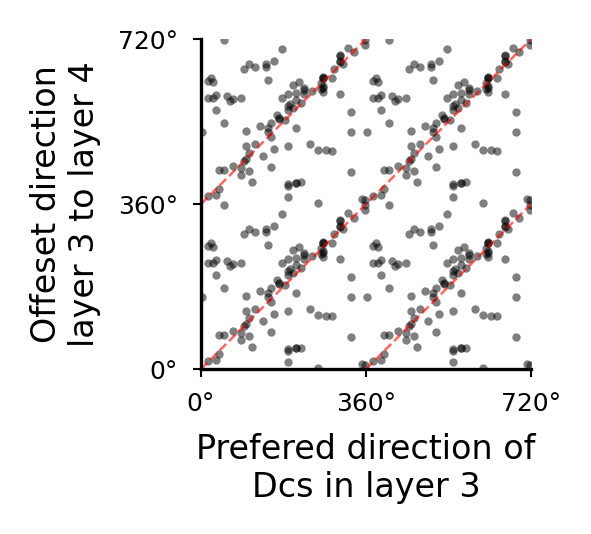

In [19]:
# ============================================================
# Scatter for 4-layer model:
#   x = Conj HD preferred direction
#   y = direction from Conj HD CoM to signed Conj→mEC weighted CoM
#   dots = black
#   plus Spearman correlation
#
# Requires variables from the previous 4-layer block:
#   high_hd_local_ns_ids
#   conj_orig_ids_ns
#   conj_com_xy_all
#   mec_com_xy_all
#   W_conj_to_mec
#   conj_tuning_all
#   centers
#   conj_directional_mvl
#   signed_weighted_relative_com
#   signed_norm_mode
#   H, W_map
#   eps
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ------------------------------------------------------------
# Helper: circular wrap to [-pi, pi]
# ------------------------------------------------------------
def wrap_to_pi(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


# ------------------------------------------------------------
# Compute scatter variables
# ------------------------------------------------------------
hd_pref_dirs = []
weighted_com_dirs = []
angle_diffs = []
hd_mvl_list = []
conj_local_ns_list = []
conj_orig_list = []

target_mec_ids = np.arange(W_conj_to_mec.shape[0])
target_mec_coms = mec_com_xy_all[target_mec_ids]

for conj_local_ns in high_hd_local_ns_ids:
    # index within non-silent Conj metrics -> original Conj ID
    conj_orig = conj_orig_ids_ns[conj_local_ns]

    x_conj, y_conj = conj_com_xy_all[conj_orig]

    # Conj -> all mEC weights
    # W_conj_to_mec[target_mEC_id, source_Conj_id]
    signed_weights_mec = W_conj_to_mec[target_mec_ids, conj_orig]

    x_pop, y_pop, valid_mec = signed_weighted_relative_com(
        source_com=conj_com_xy_all[conj_orig],
        target_coms=target_mec_coms,
        signed_weights=signed_weights_mec,
        norm_mode=signed_norm_mode,
        eps=eps,
        clip_to_bounds=(H, W_map),
    )

    if not (
        np.isfinite(x_conj)
        and np.isfinite(y_conj)
        and np.isfinite(x_pop)
        and np.isfinite(y_pop)
    ):
        continue

    dx = x_pop - x_conj
    dy = y_pop - y_conj

    if np.sqrt(dx**2 + dy**2) <= eps:
        continue

    # x-axis: Conj HD preferred direction from angular tuning
    hd_pref = centers[np.argmax(conj_tuning_all[conj_orig])]

    # y-axis: direction from Conj HD CoM to weighted mEC CoM
    com_dir = np.arctan2(dy, dx)

    hd_pref_dirs.append(wrap_to_pi(hd_pref))
    weighted_com_dirs.append(wrap_to_pi(com_dir))
    angle_diffs.append(wrap_to_pi(com_dir - hd_pref))
    hd_mvl_list.append(conj_directional_mvl[conj_local_ns])
    conj_local_ns_list.append(conj_local_ns)
    conj_orig_list.append(conj_orig)

hd_pref_dirs = np.asarray(hd_pref_dirs)
weighted_com_dirs = np.asarray(weighted_com_dirs)
angle_diffs = np.asarray(angle_diffs)
hd_mvl_list = np.asarray(hd_mvl_list)
conj_local_ns_list = np.asarray(conj_local_ns_list)
conj_orig_list = np.asarray(conj_orig_list)

print(f"Valid high-HD Conj cells plotted: {len(hd_pref_dirs)}")


# ------------------------------------------------------------
# Spearman correlation
# ------------------------------------------------------------
valid_corr = (
    np.isfinite(hd_pref_dirs)
    & np.isfinite(weighted_com_dirs)
)

if np.sum(valid_corr) >= 3:
    rho, pval = spearmanr(
        hd_pref_dirs[valid_corr],
        weighted_com_dirs[valid_corr],
    )
else:
    rho, pval = np.nan, np.nan

print(f"Spearman rho = {rho:.4f}, p = {pval:.4g}, n = {np.sum(valid_corr)}")


# # ------------------------------------------------------------
# # Plot scatter, normal circular range [-pi, pi]
# # ------------------------------------------------------------
# fig, ax = plt.subplots(figsize=(2.6, 2.4), dpi=300)

# ax.scatter(
#     hd_pref_dirs,
#     weighted_com_dirs,
#     color="black",
#     s=18,
#     alpha=0.75,
#     linewidth=0,
# )

# # Reference y = x line
# xx = np.linspace(-np.pi, np.pi, 200)
# ax.plot(xx, xx, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

# ax.set_xlim(-np.pi, np.pi)
# ax.set_ylim(-np.pi, np.pi)

# ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
# ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])

# ax.set_xticklabels(
#     [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"],
#     fontsize=8,
# )
# ax.set_yticklabels(
#     [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"],
#     fontsize=8,
# )

# ax.set_xlabel("Conj HD preferred direction", fontsize=8)
# ax.set_ylabel("Conj CoM → weighted mEC CoM direction", fontsize=8)

# ax.tick_params(axis="both", labelsize=8, length=2, width=0.5)
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)

# ax.set_title(
#     f"Conj→mEC signed weights\n"
#     f"Spearman ρ={rho:.2f}, p={pval:.2g}, n={np.sum(valid_corr)}",
#     fontsize=8,
# )

# ax.set_aspect("equal")

# plt.tight_layout()
# plt.show()


# ============================================================
# Repeated circular scatter:
#   repeat as 2x2 tiles:
#      (x, y)
#      (x + 2π, y)
#      (x, y + 2π)
#      (x + 2π, y + 2π)
#   axis range: [-π, 3π]
#   dots = black
# ============================================================

x0 = hd_pref_dirs
y0 = weighted_com_dirs

valid = (
    np.isfinite(x0)
    & np.isfinite(y0)
)

x0 = x0[valid]
y0 = y0[valid]

# Repeat as 2x2 tiles
x_rep = np.concatenate([
    x0,
    x0 + 2 * np.pi,
    x0,
    x0 + 2 * np.pi,
])

y_rep = np.concatenate([
    y0,
    y0,
    y0 + 2 * np.pi,
    y0 + 2 * np.pi,
])

fig, ax = plt.subplots(figsize=(2, 2), dpi=300)

ax.scatter(
    x_rep,
    y_rep,
    color="black",
    s=4,
    alpha=0.5,
    linewidth=0,
)

# Reference y = x in repeated space
ax.plot([-np.pi, 3 * np.pi], [-np.pi, 3 * np.pi], color="red", linestyle="--", linewidth=0.6, alpha=0.6)
ax.plot([-np.pi, np.pi], [np.pi, 3*np.pi], color="red", linestyle="--", linewidth=0.6, alpha=0.6)
ax.plot([np.pi, 3*np.pi], [-np.pi, np.pi], color="red", linestyle="--", linewidth=0.6, alpha=0.6)

ax.set_xlim(-np.pi, 3 * np.pi)
ax.set_ylim(-np.pi, 3 * np.pi)

ticks = [-np.pi,np.pi, 3 * np.pi]
ticklabels = ["0°", "360°", r"720°"]

ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(ticklabels, fontsize=8)
ax.set_yticklabels(ticklabels, fontsize=8)

ax.set_xlabel("Prefered direction of\nDcs in layer 3", fontsize=8)
ax.set_ylabel("Offeset direction\nlayer 3 to layer 4", fontsize=8)

ax.tick_params(axis="both", labelsize=6, length=2, width=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ax.set_title(
#     f"Conj→mEC signed weights\n"
#     f"Spearman ρ={rho:.2f}, p={pval:.2g}, n={np.sum(valid_corr)}",
#     fontsize=8,
# )

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig(
    f"./docs/layer3to4_stats.pdf",
    bbox_inches="tight", pad_inches=0.03)